# Phase 2 & 3: RUL Labeling, Feature Engineering & Classical ML Baselines
### Linear Regression vs. Random Forest vs. XGBoost

In this notebook, we implement piecewise-linear RUL labeling, extract rolling window statistical features (mean, std, min, max, slope), and train three classical regression algorithms to establish the benchmark.

In [1]:
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.loader import load_dataset
from src.data.rul_labeling import add_rul_labels, add_test_rul_labels
from src.data.splits import train_val_split_by_engine
from src.features.engineering import get_informative_features, fit_transform_scaler, extract_tabular_features
from src.models.ml_baselines import train_and_eval_ml_models
from src.utils.config import RUL_CAP, RANDOM_SEED

sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Preprocessing & Rolling Statistics Extraction

In [2]:
train_df, test_df, rul_df = load_dataset('FD001')
feature_cols = get_informative_features(train_df)

train_df_rul = add_rul_labels(train_df, rul_cap=RUL_CAP, piecewise=True)
test_df_rul = add_test_rul_labels(test_df, rul_df, rul_cap=RUL_CAP, piecewise=True)

train_scaled, test_scaled, scaler = fit_transform_scaler(train_df_rul, test_df_rul, feature_cols)
train_split, val_split = train_val_split_by_engine(train_scaled, val_ratio=0.2, random_state=RANDOM_SEED)

tr_eng = extract_tabular_features(train_split, feature_cols)
va_eng = extract_tabular_features(val_split, feature_cols)
te_eng = extract_tabular_features(test_scaled, feature_cols)
te_last = te_eng.groupby('unit_number').last().reset_index()

tab_cols = [c for c in tr_eng.columns if c not in ['unit_number', 'time_in_cycles', 'setting_1', 'setting_2', 'setting_3', 'raw_rul', 'RUL']]
print(f'Total Tabular Features Extracted: {len(tab_cols)}')

Total Tabular Features Extracted: 202


## 2. Train Classical Models & Evaluate on Test Set
Metrics: MAE, RMSE, R², and the NASA asymmetric score.

In [3]:
X_tr = tr_eng[tab_cols].values
y_tr = tr_eng['RUL'].values
X_va = va_eng[tab_cols].values
y_va = va_eng['RUL'].values
X_te = te_last[tab_cols].values
y_te = te_last['RUL'].values

metrics_df, models, importances = train_and_eval_ml_models(
    X_tr, y_tr, X_va, y_va, X_te, y_te, feature_names=tab_cols
)
metrics_df

Training Linear Regression...


Training Random Forest...


Training XGBoost...


,Model,Val_MAE,Val_RMSE,Val_R2,Val_NASA_Score,Test_MAE,Test_RMSE,Test_R2,Test_NASA_Score
0,Linear Regression,13.094461,16.187982,0.849413,17282.079215,14.327271,17.979510,0.798699,529.686430
1,Random Forest,10.436467,15.237286,0.866581,17414.744785,12.065066,17.211861,0.815521,553.375832
2,XGBoost,10.063608,14.390672,0.880995,14942.211200,11.491068,16.820532,0.823815,604.049393


## 3. Feature Importance Analysis (Random Forest & XGBoost)
Inspect which rolling sensor features contribute most to the RUL predictions.

C:\Users\Parth\AppData\Local\Temp\ipykernel_23636\3855669542.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, ax=axes[idx], palette='viridis')
C:\Users\Parth\AppData\Local\Temp\ipykernel_23636\3855669542.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, ax=axes[idx], palette='viridis')


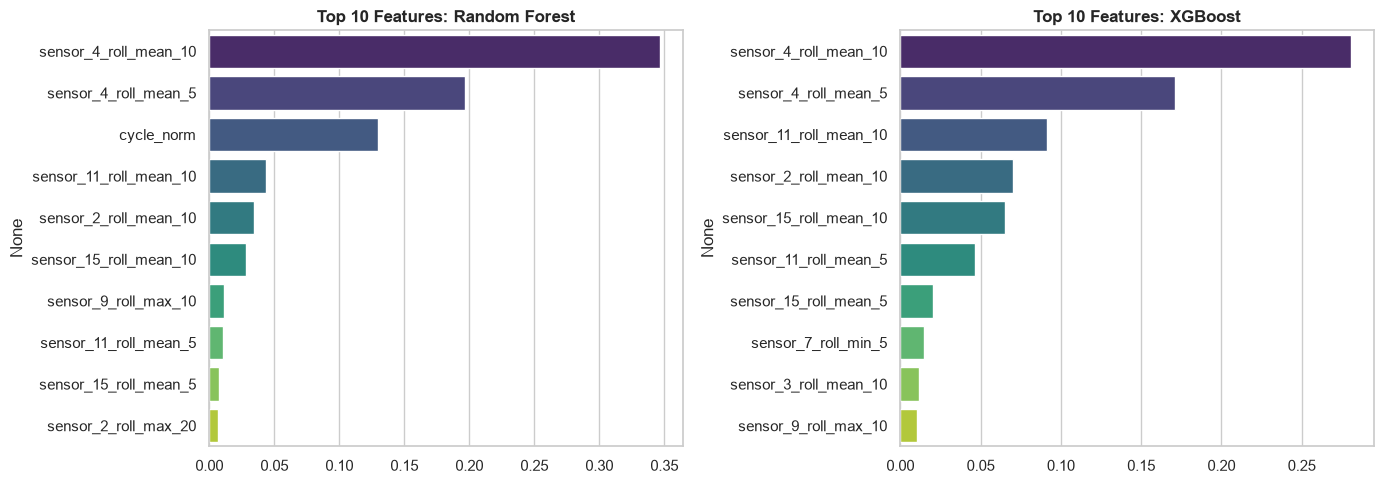

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models_to_plot = [m for m in ['Random Forest', 'XGBoost'] if m in importances]
for idx, m_name in enumerate(models_to_plot):
    imp = importances[m_name]
    top10 = imp.head(10)
    sns.barplot(x=top10.values, y=top10.index, ax=axes[idx], palette='viridis')
    axes[idx].set_title(f'Top 10 Features: {m_name}', fontweight='bold')
plt.tight_layout()
plt.show()

> **Key Takeaway**: Non-linear tree models (Random Forest RMSE: 17.21, XGBoost RMSE: 16.82) outperform linear regression (RMSE: 17.98). Rolling averages and standard deviations over 10- and 20-cycle windows for sensors 4, 11, and 12 dominate feature importance, showing that multi-cycle smoothing captures trend clearer than single-cycle noise.